# **Canada Immigration Data Analysis**

**Period:** 1980–2013

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab


**Project Overview**

This project analyzes historical immigration records to Canada from 1980 to 2013. It explores annual trends, identifies the five countries with the highest cumulative recorded counts, and compares their immigration patterns.


**Business Questions**

1. How did annual immigration counts change from 1980 to 2013?
2. Which five countries had the highest cumulative counts?
3. How did annual trends differ among these five countries?


**Dataset:** `canada_immrigration_dataset.xlsx`, sheet `Canada by Citizenship`.

**Source:** IBM Skills Network – Canada.xlsx

*Scope: Results describe this historical dataset only. They should not be presented as current Canadian immigration statistics.*

### **1. Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from urllib.request import urlretrieve

sns.set_theme(style="whitegrid")

### **2. Load Dataset**

Load the workbook and inspect the first records. If automatic download fails, upload `Canada.xlsx` to the Colab session and set `FILE_PATH` to its filename.

In [2]:
DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.xlsx"
FILE_PATH = Path("Canada.xlsx")

if not FILE_PATH.exists():
    try:
        urlretrieve(DATA_URL, FILE_PATH)
    except Exception:
        from google.colab import files
        uploaded = files.upload()
        FILE_PATH = Path(next(iter(uploaded)))

raw_df = pd.read_excel(
    FILE_PATH,
    sheet_name="Canada by Citizenship",
    skiprows=range(20),
    skipfooter=2
)

print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Dataset shape: (195, 43)


,Type,Coverage,OdName,AREA,AreaName,REG,RegName,DEV,DevName,1980,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Immigrants,Foreigners,Afghanistan,935,Asia,5501,Southern Asia,902,Developing regions,16,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Immigrants,Foreigners,Albania,908,Europe,925,Southern Europe,901,Developed regions,1,...,1450,1223,856,702,560,716,561,539,620,603
2,Immigrants,Foreigners,Algeria,903,Africa,912,Northern Africa,902,Developing regions,80,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,Immigrants,Foreigners,American Samoa,909,Oceania,957,Polynesia,902,Developing regions,0,...,0,0,1,0,0,0,0,0,0,0
4,Immigrants,Foreigners,Andorra,908,Europe,925,Southern Europe,901,Developed regions,0,...,0,0,1,1,0,0,0,0,1,1


**Result note:** Record the actual row and column counts. Confirm that the preview contains country metadata and annual immigration columns.

### **3. Data Understanding**

In [3]:
print("Columns:", raw_df.columns.tolist())
raw_df.info()
display(raw_df.describe(include="all").T)

Columns: ['Type', 'Coverage', 'OdName', 'AREA', 'AreaName', 'REG', 'RegName', 'DEV', 'DevName', 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 43 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Type      195 non-null    object
 1   Coverage  195 non-null    object
 2   OdName    195 non-null    object
 3   AREA      195 non-null    int64 
 4   AreaName  195 non-null    object
 5   REG       195 non-null    int64 
 6   RegName   195 non-null    object
 7   DEV       195 non-null    int64 
 8   DevName   195 non-null    object
 9   1980      195 non-null    int64 
 10  1981      195 non-null    int64 
 11  1982      195 non-null    int64 
 12  1983      195 non-null    int64 
 13  1984      195 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,195,1,Immigrants,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Coverage,195,2,Foreigners,194,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OdName,195,195,Afghanistan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AREA,195.0,NaN,NaN,NaN,912.764103,13.082835,903.0,903.0,908.0,922.0,935.0
AreaName,195,6,Africa,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
REG,195.0,NaN,NaN,NaN,1249.015385,1185.526885,905.0,914.0,922.0,925.5,5501.0
RegName,195,22,Western Asia,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEV,195.0,NaN,NaN,NaN,901.753846,0.431878,901.0,902.0,902.0,902.0,902.0
DevName,195,2,Developing regions,147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1980,195.0,NaN,NaN,NaN,508.394872,1949.588546,0.0,0.0,13.0,251.5,22045.0


**Result note:** Identify the country field, metadata fields, year columns, and data types. The workbook is expected to contain annual values for 1980–2013; verify this from the imported columns.

### **4. Data Cleaning & Preparation**

In [4]:
df = raw_df.copy()

# Keep useful metadata and annual values; remove technical classification fields.
drop_cols = ["AREA", "REG", "DEV", "Type", "Coverage"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

df = df.rename(columns={
    "OdName": "Country",
    "AreaName": "Continent",
    "RegName": "Region",
    "DevName": "Development"
})

year_cols = [c for c in df.columns if str(c).isdigit()]
year_map = {c: int(c) for c in year_cols}
df = df.rename(columns=year_map)
years = sorted(year_map.values())

for year in years:
    df[year] = pd.to_numeric(df[year], errors="coerce")

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate country names:", int(df["Country"].duplicated().sum()))

# Set country as index for country-level analysis.
df = df.set_index("Country").sort_index()
print("Prepared shape:", df.shape)
display(df.head())

Missing values: 0
Duplicate rows: 0
Duplicate country names: 0
Prepared shape: (195, 37)


,Continent,Region,Development,1980,1981,1982,1983,1984,1985,1986,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1450,1223,856,702,560,716,561,539,620,603
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,0,1,1,0,0,0,0,1,1


**Result note:** Check the missing-value and duplicate counts. Investigate any duplicate country names before aggregating. Do not automatically delete valid zero counts or records without checking their meaning.

### **5. Exploratory Data Analysis (EDA)**

In [5]:
# Reshape annual columns into one row per country and year.
immigration = (
    df.reset_index()
      .melt(
          id_vars=["Country"],
          value_vars=years,
          var_name="Year",
          value_name="Immigrants"
      )
)

immigration["Year"] = immigration["Year"].astype(int)
immigration["Immigrants"] = pd.to_numeric(immigration["Immigrants"], errors="coerce")

print("Countries:", immigration["Country"].nunique())
print("Years:", immigration["Year"].nunique())
print("Total recorded count:", f"{immigration['Immigrants'].sum():,.0f}")
display(immigration["Immigrants"].describe())

Countries: 195
Years: 34
Total recorded count: 6,409,153


,Immigrants
count,6630.000000
mean,966.689744
std,3216.945526
min,0.000000
25%,6.000000
50%,99.000000
75%,581.750000
max,42584.000000


**Result note:** The total is the sum of country-year counts across 1980–2013, not a current population estimate. Use the summary statistics to understand the distribution before interpreting the trends.

### **6. Data Analysis**

**6.1 Overall Immigration Trend**

Aggregate recorded counts by year and calculate year-over-year change.

In [6]:
annual = immigration.groupby("Year", as_index=False)["Immigrants"].sum()
annual["YoY_Change"] = annual["Immigrants"].diff()

peak = annual.loc[annual["Immigrants"].idxmax()]
largest_increase = annual.loc[annual["YoY_Change"].idxmax()]
largest_decrease = annual.loc[annual["YoY_Change"].idxmin()]

display(annual.head())
print(f"Highest annual total: {int(peak['Year'])} — {peak['Immigrants']:,.0f}")
print(f"Largest increase: {int(largest_increase['Year'])} — {largest_increase['YoY_Change']:+,.0f}")
print(f"Largest decrease: {int(largest_decrease['Year'])} — {largest_decrease['YoY_Change']:+,.0f}")

,Year,Immigrants,YoY_Change
0,1980,99137,NaN
1,1981,110563,11426.0
2,1982,104271,-6292.0
3,1983,75550,-28721.0
4,1984,73417,-2133.0


Highest annual total: 2010 — 276,956
Largest increase: 1987 — +48,723
Largest decrease: 1998 — -32,158


**6.2 Top 5 Countries**

Rank countries by their cumulative recorded counts across the full period.

In [7]:
country_totals = (
    immigration.groupby("Country", as_index=False)["Immigrants"]
    .sum()
    .sort_values("Immigrants", ascending=False)
)

top5 = country_totals.head(5)
top5_names = top5["Country"].tolist()
display(top5)

,Country,Immigrants
79,India,691904
36,China,659962
183,United Kingdom of Great Britain and Northern I...,551500
136,Philippines,511391
130,Pakistan,241600


**6.3 Compare Top 5 Country Trends**

In [8]:
top5_trend = immigration[immigration["Country"].isin(top5_names)]
top5_pivot = top5_trend.pivot(
    index="Year", columns="Country", values="Immigrants"
).sort_index()

display(top5_pivot.head())

Country,China,India,Pakistan,Philippines,United Kingdom of Great Britain and Northern Ireland
Year,,,,,
1980,5123,8880,978,6051,22045
1981,6682,8670,972,5921,24796
1982,3308,8147,1201,5249,20620
1983,1863,7338,900,4562,10015
1984,1527,5704,668,3801,10170


### **7. Data Visualization**

**7.1 Overall Immigration Trend**

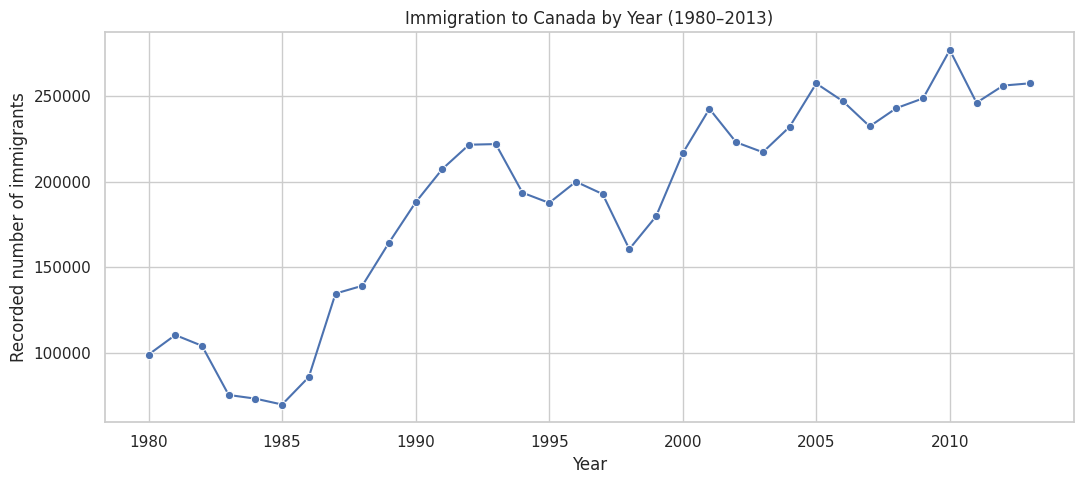

In [9]:
plt.figure(figsize=(11, 5))
sns.lineplot(data=annual, x="Year", y="Immigrants", marker="o")
plt.title("Immigration to Canada by Year (1980–2013)")
plt.xlabel("Year")
plt.ylabel("Recorded number of immigrants")
plt.tight_layout()
plt.show()

**7.2 Top 5 Countries by Cumulative Count**

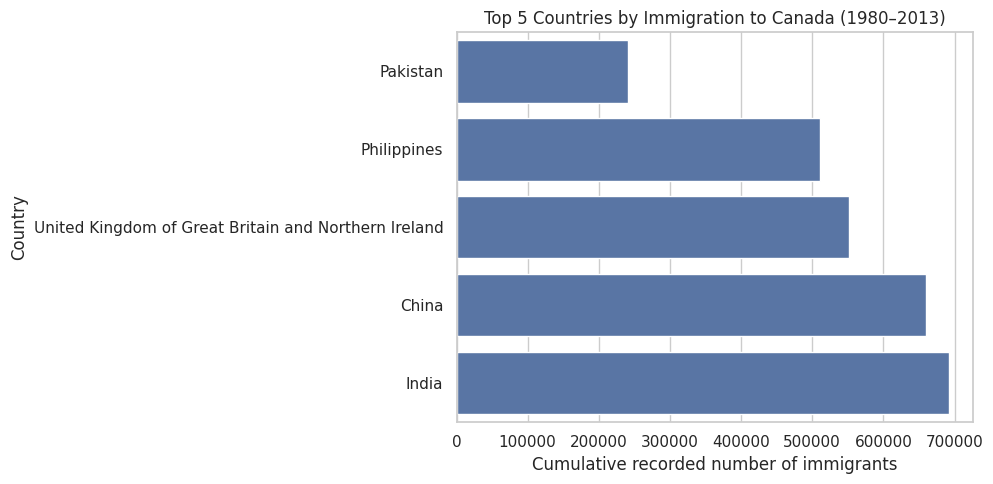

In [10]:
plt.figure(figsize=(10, 5))
sns.barplot(data=top5.sort_values("Immigrants"), x="Immigrants", y="Country")
plt.title("Top 5 Countries by Immigration to Canada (1980–2013)")
plt.xlabel("Cumulative recorded number of immigrants")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

**7.3 Annual Trends of the Top 5 Countries**

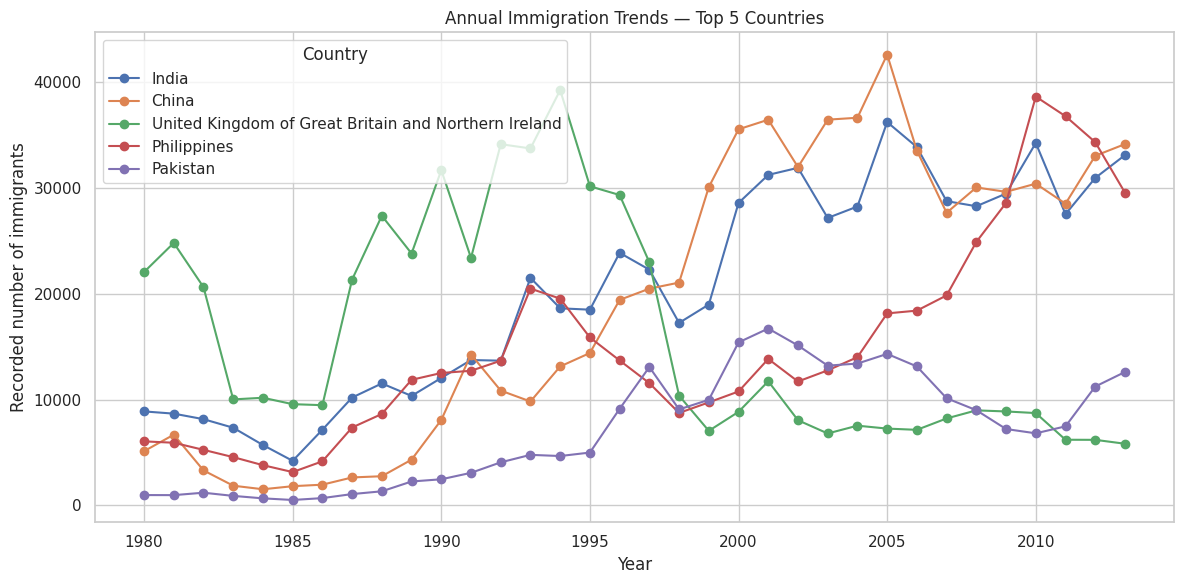

In [11]:
plt.figure(figsize=(12, 6))
for country in top5_names:
    plt.plot(top5_pivot.index, top5_pivot[country], marker="o", label=country)

plt.title("Annual Immigration Trends — Top 5 Countries")
plt.xlabel("Year")
plt.ylabel("Recorded number of immigrants")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

**Result note:** Use the charts to describe the overall direction, the five highest cumulative country totals, and differences in country-level trends. Avoid claiming a cause for a peak or decline unless supported by separate evidence.

### **8. Key Findings**

In [12]:
top_country = top5.iloc[0]

print("KEY FINDINGS")
print(f"1. The highest annual total occurred in {int(peak['Year'])}: {peak['Immigrants']:,.0f}.")
print(f"2. {top_country['Country']} ranked first by cumulative recorded count: {top_country['Immigrants']:,.0f}.")
print("3. The five leading countries show the annual patterns displayed in the comparison chart.")
print(f"4. The largest year-over-year increase occurred in {int(largest_increase['Year'])}.")
print(f"5. The largest year-over-year decrease occurred in {int(largest_decrease['Year'])}.")

KEY FINDINGS
1. The highest annual total occurred in 2010: 276,956.
2. India ranked first by cumulative recorded count: 691,904.
3. The five leading countries show the annual patterns displayed in the comparison chart.
4. The largest year-over-year increase occurred in 1987.
5. The largest year-over-year decrease occurred in 1998.


**Interpretation:** Review the calculated results and charts, then add one or two sentences explaining the most meaningful patterns. Do not leave generic findings if the output supports more specific observations.

### **9. Recommendations**

- Use the historical trends as context for further research, not as a forecast of current immigration.
- Examine leading countries separately because their annual patterns may differ.
- Investigate years with large changes using reliable historical, policy, or economic sources before explaining possible causes.
- Consider additional variables or population-adjusted measures for deeper analysis.

### **10. Conclusion**

This project explored recorded immigration to Canada from 1980 to 2013 using Python. It analyzed annual trends, ranked countries by cumulative recorded counts, and compared patterns among the five leading countries. Complete the conclusion with the actual findings after running the notebook.

### **11. Export Results**

In [13]:
# Export key tables for documentation or further use.
annual.to_csv("annual_immigration_trend.csv", index=False)
top5.to_csv("top5_countries.csv", index=False)
immigration.to_csv("canada_immigration_long.csv", index=False)

print("Analysis results exported.")

Analysis results exported.
